# Apprentissage de représentation et triplet loss

## Partie C : recommandation de jeux de société, embeddings et multi-loss

Vincent Guigue (vincent.guigue@agroparistech.fr)

Énoncé dérivé de celui de Nicolas Baskiotis (nicolas.baskiotis@sorbonne-universite.fr) -- MLIA/ISIR, Sorbonne Université

**Plan :** on apprend des représentations (embeddings) de jeux et d'utilisateurs pour **prédire des notes** (comme dans 3_0, mais avec un MLP) ; on constate que ces représentations n'encodent pas le contenu des jeux ; on ajoute alors une **triplet loss** (cf. 3_1) sur les catégories des jeux pour structurer l'espace.

## Table des matières

- [0. Configuration (device, tensorboard)](#sec-1)
- [1. Jeu de données de recommandation](#sec-2)
  - [1.1 Chargement](#sec-3)
  - [1.2 Filtrage](#sec-4)
- [2. Préparation des données](#sec-5)
- [3. Le modèle](#sec-6)
- [4. Apprentissage](#sec-7)
- [5. Visualisation des embeddings](#sec-8)
- [6. Multi-loss : exploiter les catégories des jeux avec la triplet loss](#sec-9)
  - [6.1 Pré-traitement des catégories (fourni)](#sec-10)
  - [6.2 Tirage des triplets](#sec-11)
  - [6.3 Apprentissage multi-loss](#sec-12)

# <a id="sec-1"></a>0. Configuration (device, tensorboard)

In [4]:
import copy
import random
import time
from collections import defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

# Sélection du device : GPU NVIDIA (cuda) > GPU Apple (mps) > CPU
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
# NB : les modèles de ce notebook sont petits, le CPU est souvent aussi rapide que mps
# device = torch.device("cpu")

torch.manual_seed(0)
random.seed(0)
print("device :", device)

device : mps


In [5]:
from torch.utils.tensorboard import SummaryWriter

import tempfile
TB_PATH = Path(tempfile.gettempdir()) / "logs" / "module3"
TB_PATH.mkdir(parents=True, exist_ok=True)
TB_INLINE = True   # True : tensorboard affiché dans le notebook ; False : le lancer soi-même dans un terminal
print(f"Pour lancer tensorboard dans un terminal : tensorboard --logdir {TB_PATH}")
if TB_INLINE:
    %load_ext tensorboard
    %tensorboard --logdir {TB_PATH}

Pour lancer tensorboard dans un terminal : tensorboard --logdir C:\Users\THEOPO~1\AppData\Local\Temp\logs\module3
The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


Reusing TensorBoard on port 6006 (pid 56739), started 0:02:29 ago. (Use '!kill 56739' to kill it.)

# <a id="sec-2"></a>1. Jeu de données de recommandation

Ce jeu de données est issu d'un célèbre site sur les jeux de société. Il contient les fichiers suivants (sans ligne d'entête) :

* `users.csv` : liste des utilisateurs et de leur identifiant sous la forme `(nickname, id)`
* `jeux.csv` : liste des jeux sous la forme `(id, slug, titre, titre complet, résumé, catégories, infos)` ; les catégories sont séparées par des `|`
* `avis.csv` : liste des avis sous la forme `(id, id_jeu, id_user, titre, nickname, date, note, titre commentaire, commentaire)` ; les notes vont de 0 à 10

Dans ce notebook, on s'intéresse uniquement aux notes données aux jeux par les utilisateurs, sans regarder le texte des commentaires. L'objectif est de prédire la note qu'un utilisateur donne à un jeu. Ce problème peut être vu comme de la régression sur la note, ou comme un problème de classification multi-classes en discrétisant la note : on choisit ici la régression.

## <a id="sec-3"></a>1.1 Chargement

In [6]:
# pour Colab (cf. ci-dessous pour travailler en local)
# ## Télécharger le fichier donnees_jds.zip dans votre google drive
# from google.colab import drive
# drive.mount('/content/drive/', force_remount=True)
# ## Changer le PATH vers le fichier de données
# PATH = "/content/drive/MyDrive/data/data_jds/"
# # On décompresse le fichier, les fichiers seront au niveau de /content
# !unzip $PATH"donnees_jds.zip"
# PATH = "./"

In [7]:
# local
PATH = "data/donnees_jds/"

# on ne lit que les colonnes utiles des avis : (id_jeu, id_user, note)
avis = pd.read_csv(PATH + "avis.csv", header=None, usecols=[1, 2, 6], names=["game", "user", "note"])
jeux = pd.read_csv(PATH + "jeux.csv", header=None,
                   names=["id", "slug", "titre", "titre_complet", "resume", "categories", "infos"])
dic_jeux = dict(zip(jeux["id"], jeux["titre"]))    # id du jeu -> titre
print(f"{len(avis)} avis, {len(jeux)} jeux")
avis.head()

142489 avis, 16873 jeux


,game,user,note
0,1801,0,8.0
1,1801,1,7.0
2,1801,2,7.0
3,1801,3,7.0
4,1801,4,8.0


## <a id="sec-4"></a>1.2 Filtrage

Nous allons dans un premier temps filtrer les données pour ne garder que des utilisateurs et des jeux ayant suffisamment de notes (sinon, impossible d'apprendre une représentation fiable).

**Note :** on se rend vite compte que ce filtrage n'est pas si évident : supprimer des jeux peu notés fait baisser le nombre d'avis de certains utilisateurs, qui peuvent alors passer sous le seuil, et vice-versa. On procède donc de manière itérative, jusqu'à convergence.

In [8]:
def filtre(df, ths_g, ths_u):
    """garde les jeux ayant plus de ths_g notes et les utilisateurs ayant plus de ths_u notes (itératif)"""
    i = 0
    while True:
        n, n_g, n_u = len(df), df["game"].nunique(), df["user"].nunique()
        print(f"Boucle {i} : {n_g} jeux, {n_u} utilisateurs, {n} notes, densité {n / (n_g * n_u):.3f}")
        df = df[df.groupby("game")["game"].transform("size") > ths_g]   # nb de notes du jeu de chaque ligne
        df = df[df.groupby("user")["user"].transform("size") > ths_u]
        i += 1
        if len(df) == n:    # plus rien ne bouge
            return df.copy()

data_dense = filtre(avis, 30, 30)   # on peut jouer avec les seuils

Boucle 0 : 10549 jeux, 11201 utilisateurs, 142489 notes, densité 0.001
Boucle 1 : 1224 jeux, 628 utilisateurs, 55883 notes, densité 0.073
Boucle 2 : 689 jeux, 505 utilisateurs, 41598 notes, densité 0.120
Boucle 3 : 628 jeux, 490 utilisateurs, 39465 notes, densité 0.128
Boucle 4 : 621 jeux, 486 utilisateurs, 39140 notes, densité 0.130
Boucle 5 : 619 jeux, 486 utilisateurs, 39080 notes, densité 0.130


On observe rapidement les caractéristiques du jeu de données restant :

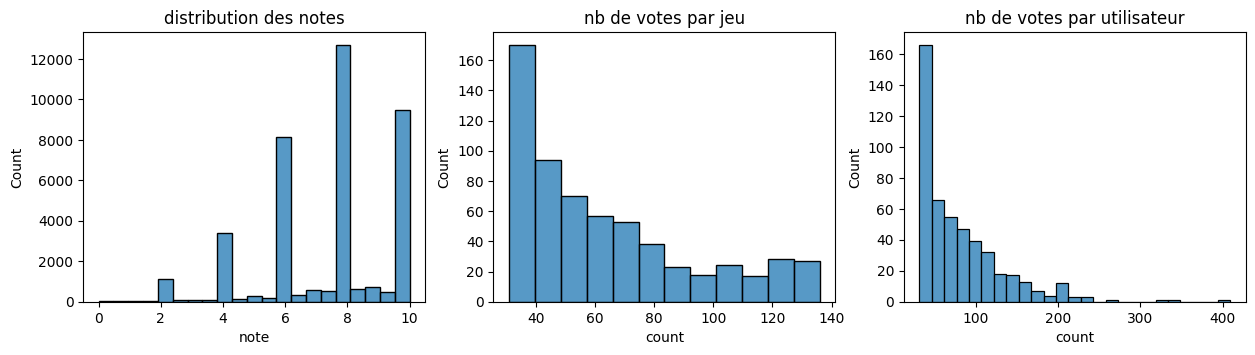

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
sns.histplot(data_dense["note"], bins=21, ax=axes[0]).set_title("distribution des notes")
sns.histplot(data_dense["game"].value_counts(), ax=axes[1]).set_title("nb de votes par jeu")
sns.histplot(data_dense["user"].value_counts(), ax=axes[2]).set_title("nb de votes par utilisateur");

# <a id="sec-5"></a>2. Préparation des données

La fonction suivante :
- ré-indexe les jeux et les utilisateurs dans $[0, N[$ (pour les `nn.Embedding`),
- normalise les notes dans $[0, 1]$,
- découpe les données en **train / validation / test** (70 / 10 / 20 %), de manière stratifiée par utilisateur : chaque utilisateur a 70 % de ses notes en train, etc. (sinon, impossible de prédire pour un utilisateur absent du train).

Pourquoi un ensemble de validation ? L'apprentissage utilise l'*early stopping* : on garde le modèle de l'époque qui a la meilleure loss... sur un ensemble qui ne doit pas être celui du test (sinon, la performance de test serait optimiste). Le test ne sert qu'**une fois**, à la fin.

In [10]:
NOTE_MIN, NOTE_MAX = 0, 10

def prepare_dataloaders(df, splits=(0.7, 0.1), batch_size=128, seed=0):
    """df : (game, user, note) -> dataloaders {'train', 'val', 'test'}, idx2games, idx2users"""
    idx2games = np.sort(df["game"].unique())
    idx2users = np.sort(df["user"].unique())
    df = df.assign(g=df["game"].map({g: k for k, g in enumerate(idx2games)}),
                   u=df["user"].map({u: k for k, u in enumerate(idx2users)}),
                   y=(df["note"] - NOTE_MIN) / (NOTE_MAX - NOTE_MIN))
    # split stratifié par utilisateur : rang de chaque note (après mélange) parmi les notes de son utilisateur
    df = df.sample(frac=1, random_state=seed)
    rank = df.groupby("u").cumcount()
    size = df.groupby("u")["u"].transform("size")
    part = np.where(rank < (splits[0] * size).astype(int), "train",
                    np.where(rank < ((splits[0] + splits[1]) * size).astype(int), "val", "test"))
    loaders = {}
    for name in ["train", "val", "test"]:
        d = df[part == name]
        ds = TensorDataset(torch.tensor(d["g"].values), torch.tensor(d["u"].values),
                           torch.tensor(d["y"].values, dtype=torch.float32))
        loaders[name] = DataLoader(ds, batch_size=batch_size, shuffle=(name == "train"))
    return loaders, idx2games, idx2users

dataloaders, idx2games, idx2users = prepare_dataloaders(data_dense)
print({k: len(v.dataset) for k, v in dataloaders.items()}, f"| {len(idx2games)} jeux, {len(idx2users)} utilisateurs")

{'train': 27121, 'val': 3891, 'test': 8068} | 619 jeux, 486 utilisateurs


# <a id="sec-6"></a>3. Le modèle

Il ne reste plus qu'à définir un modèle pour la prédiction de notes. L'architecture est très simple :

* une couche d'embedding pour les jeux, de dimension $\ell$ (`self.games`),
* une couche d'embedding pour les utilisateurs, de dimension $\ell$ (`self.users`),
* les sorties de ces deux couches sont concaténées pour former un vecteur de taille $2\ell$ ; ce vecteur passe ensuite dans un MLP (`self.net`) qui possède $2\ell$ entrées, une couche cachée de taille $\ell$ avec l'activation `act`, et une sortie (la note prédite).

PyTorch fournit le module [`nn.Embedding`](https://pytorch.org/docs/stable/generated/torch.nn.Embedding.html) pour la couche de représentation. `forward(igames, iusers)` reçoit deux vecteurs d'indices de taille `batch` et renvoie un vecteur de taille `batch` (penser à `.squeeze(-1)`).

*Différence avec 3_0 :* la factorisation de matrice combine les deux représentations par un produit scalaire ; ici, c'est un MLP qui apprend la fonction de combinaison.

In [ ]:
class RecoRegNet(nn.Module):
    def __init__(self, n_games, n_users, latent_dim=25, act=nn.Tanh, name="reco"):
        super().__init__()
        self.name = name
        # Définir: 
        # - self.games  => emb
        # - self.users => emb
        # - self.net => decision
        ##  TODO 

    def forward(self, igames, iusers):
        ##  TODO 

In [12]:
# vérification : faire passer un petit batch (sortie arbitraire, c'est pour vérifier les dimensions)
reco = RecoRegNet(10, 10)
g, u = torch.tensor([0, 1, 2]), torch.tensor([0, 0, 5])
print(reco(g, u).shape)   # attendu : torch.Size([3])

torch.Size([3])


# <a id="sec-7"></a>4. Apprentissage

Une boucle d'apprentissage classique (fournie), avec :
- l'évaluation sur la validation à chaque époque et l'*early stopping* : on garde une copie des poids de la meilleure époque (`copy.deepcopy(model.state_dict())`) et on s'arrête après `early_stop` époques sans amélioration ;
- l'enregistrement dans tensorboard des loss et des histogrammes des notes prédites et réelles ;
- un argument `extra_loss` qui servira en section 6 : une fonction `extra_loss(model, batch_size)` qui renvoie un terme à ajouter au coût pendant l'apprentissage.

Les performances sont données en **RMSE dans l'unité des notes** ($\sqrt{MSE} \times 10$), plus facile à interpréter que la MSE sur des notes normalisées.

In [29]:
# noter la présence d'extra_loss => prévu pour les questions suivantes
def run_epoch(model, loader, loss_fn, optimizer=None, extra_loss=None):
    """une passe sur loader (apprentissage si optimizer est fourni) ; renvoie (MSE moyenne, prédictions, vraies notes)"""
    model.train(optimizer is not None)
    cum_loss, preds, truth = 0., [], []
    with torch.set_grad_enabled(optimizer is not None):
        for games, users, notes in loader:
            games, users, notes = games.to(device), users.to(device), notes.to(device)
            yhat = model(games, users)
            l = loss_fn(yhat, notes)
            cum_loss += l.item() * len(notes)
            if optimizer is not None:
                if extra_loss is not None:
                    l = l + extra_loss(model, len(notes))
                optimizer.zero_grad()
                l.backward()
                optimizer.step()
            preds.append(yhat.detach().cpu())
            truth.append(notes.cpu())
    return cum_loss / len(loader.dataset), torch.cat(preds), torch.cat(truth)


def rmse_notes(mse):
    return np.sqrt(mse) * (NOTE_MAX - NOTE_MIN)


def train(model, dataloaders, loss_fn=nn.MSELoss(), nb_epochs=100, lr=1e-3, early_stop=5, extra_loss=None):
    """Renvoie le meilleur modèle (selon la loss de validation)"""
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    writer = SummaryWriter(TB_PATH / f"{model.name}-{time.strftime('%H%M%S')}")
    best_l, cpt_early = float("inf"), 0
    for epoch in range(nb_epochs):
        l_train, _, _ = run_epoch(model, dataloaders["train"], loss_fn, opt, extra_loss)
        l_val, preds, truth = run_epoch(model, dataloaders["val"], loss_fn)
        writer.add_scalar("loss/train", l_train, epoch)
        writer.add_scalar("loss/val", l_val, epoch)
        writer.add_histogram("val/pred", preds, epoch)
        writer.add_histogram("val/ground", truth, epoch)
        if l_val < best_l:   # meilleur modèle : on sauvegarde (en mémoire) ses poids
            best_l, cpt_early = l_val, 0
            best_state = copy.deepcopy(model.state_dict())
            mark = "*"
        else:
            cpt_early += 1
            mark = ""
        print(f"[{model.name}] epoch {epoch} | RMSE train {rmse_notes(l_train):.3f} | val {rmse_notes(l_val):.3f} {mark}")
        if cpt_early > early_stop:
            break
    writer.close()
    model.load_state_dict(best_state)   # on récupère le meilleur modèle
    return model

In [14]:
model = train(RecoRegNet(len(idx2games), len(idx2users), latent_dim=25, name="reco"), dataloaders)

l_test, _, _ = run_epoch(model, dataloaders["test"], nn.MSELoss())
# point de comparaison : prédire toujours la note moyenne du train
mean_train = dataloaders["train"].dataset.tensors[2].mean()
y_test = dataloaders["test"].dataset.tensors[2]
print(f"\nRMSE test : modèle {rmse_notes(l_test):.3f} | prédicteur constant (moyenne) {rmse_notes(((y_test - mean_train)**2).mean().item()):.3f}")

Disabling PyTorch because PyTorch >= 2.4 is required but found 2.2.2
PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


[reco] epoch 0 | RMSE train 5.352 | val 2.237 *
[reco] epoch 1 | RMSE train 2.159 | val 2.160 *
[reco] epoch 2 | RMSE train 2.117 | val 2.138 *
[reco] epoch 3 | RMSE train 2.086 | val 2.112 *
[reco] epoch 4 | RMSE train 2.058 | val 2.099 *
[reco] epoch 5 | RMSE train 2.025 | val 2.079 *
[reco] epoch 6 | RMSE train 1.996 | val 2.063 *
[reco] epoch 7 | RMSE train 1.966 | val 2.025 *
[reco] epoch 8 | RMSE train 1.939 | val 2.008 *
[reco] epoch 9 | RMSE train 1.912 | val 1.982 *
[reco] epoch 10 | RMSE train 1.889 | val 1.993 
[reco] epoch 11 | RMSE train 1.864 | val 1.986 
[reco] epoch 12 | RMSE train 1.843 | val 1.969 *
[reco] epoch 13 | RMSE train 1.824 | val 1.956 *
[reco] epoch 14 | RMSE train 1.812 | val 1.950 *
[reco] epoch 15 | RMSE train 1.798 | val 1.968 
[reco] epoch 16 | RMSE train 1.781 | val 1.949 *
[reco] epoch 17 | RMSE train 1.768 | val 1.950 
[reco] epoch 18 | RMSE train 1.754 | val 1.947 *
[reco] epoch 19 | RMSE train 1.744 | val 1.953 
[reco] epoch 20 | RMSE train 1.731 

**Question.** Comparer le modèle au prédicteur constant. Regarder dans tensorboard (onglet *Histograms*) la distribution des notes prédites par rapport aux vraies notes : qu'observe-t-on ?

In [ ]:
##  TODO 

# <a id="sec-8"></a>5. Visualisation des embeddings

Une des meilleures implémentations de [t-SNE](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html) est disponible dans tensorboard :
1. exécuter la cellule ci-dessous, qui enregistre les embeddings des jeux avec leurs titres,
2. sélectionner l'onglet **Projector** de tensorboard (recharger la page si besoin),
3. jouer avec les options (t-SNE, recherche d'un titre, voisins).

On peut aussi regarder directement dans le notebook les plus proches voisins (similarité cosinus) des jeux les plus notés.

In [30]:
titles = [dic_jeux[g] for g in idx2games]
writer = SummaryWriter(TB_PATH / f"projector-{time.strftime('%H%M%S')}")
writer.add_embedding(model.games.weight.detach().cpu(), metadata=titles, tag="jeux_reco")
writer.close()

def voisins(E, k_game, k=5):
    """titres des k plus proches voisins (cosinus) du jeu d'indice k_game dans la matrice d'embeddings E"""
    E = F.normalize(E.detach().cpu(), dim=1)
    sims = E @ E[k_game]
    return [titles[j] for j in sims.topk(k + 1).indices[1:]]

# les 5 jeux les plus notés
top_games = [int(np.where(idx2games == g)[0][0]) for g in data_dense["game"].value_counts().index[:5]]
for k in top_games:
    print(f"{titles[k]:25s} -> {voisins(model.games.weight, k)}")

Elixir                    -> ['Xe queo !', "Thurn et Taxis : L'Aventure Postale", 'Gift Trap', 'Mikado', 'Ora & Labora']
Non Merci                 -> ['Le Tour du Monde en 80 Jours', 'Off The Dead', 'Water Lily', 'Wings of War - Famous Aces', "L'Île interdite"]
Time's Up !               -> ['Iliade', 'Duplik', 'Space Hulk', 'Innovation', 'Welcome to the Dungeon']
Pique Plume               -> ['Fight !', 'Contrario', 'Glory to Rome', 'Arriala', 'Métro']
Camelot                   -> ['Aqua Romana', 'Galaxy Trucker', 'Polarity', 'Edel, Stein & Reich', 'Bakong']


# <a id="sec-9"></a>6. Multi-loss : exploiter les catégories des jeux avec la triplet loss

Les profils doivent encoder les informations discriminantes des produits et des utilisateurs pour modéliser les affinités. Jusqu'ici, nous n'avons encodé que les traces des utilisateurs (*collaborative filtering*). L'enjeu est maintenant d'exploiter aussi des informations liées au **contenu** des produits.

Dans les données fournies, chaque jeu a une ou plusieurs **catégories** (*Placement*, *Gestion*, *Jeux de cartes*...). Il n'y a pas d'information sur les utilisateurs.

**Méthode.** On ajoute à la MSE une triplet loss (cf. 3_1) sur les embeddings des jeux :
- ancre $a$ : un jeu ayant au moins une catégorie,
- positif $p$ : un jeu qui partage une catégorie avec $a$,
- négatif $n$ : un jeu qui ne partage **aucune** catégorie avec $a$,

$$\mathcal L = \text{MSE} + \alpha \cdot \text{Triplet}\big(E_a, E_p, E_n\big)$$

**Mesure.** Pour savoir si l'espace des jeux est structuré par les catégories : pour chaque jeu, la proportion de ses 10 plus proches voisins qui partagent au moins une catégorie avec lui (*accord des k-NN*).

## <a id="sec-10"></a>6.1 Pré-traitement des catégories (fourni)

In [31]:
# catégories de chaque jeu retenu (ensemble de chaînes), dans l'ordre de nos indices
cats = dict(zip(jeux["id"], jeux["categories"].fillna("").map(lambda s: {c for c in s.split("|") if c})))
game_cats = [cats[g] for g in idx2games]

# index inverse : catégorie -> liste des jeux (indices) de cette catégorie
cat2games = defaultdict(list)
for k, cs in enumerate(game_cats):
    for c in cs:
        cat2games[c].append(k)
games_with_cat = [k for k, cs in enumerate(game_cats) if cs]

print(f"{len(games_with_cat)}/{len(game_cats)} jeux ont au moins une catégorie, {len(cat2games)} catégories")
print("catégories les plus fréquentes :", sorted(cat2games, key=lambda c: -len(cat2games[c]))[:8])

488/619 jeux ont au moins une catégorie, 146 catégories
catégories les plus fréquentes : ['Jeux de plateau', 'Placement', 'Hasard (Dé, Cartes, ...)', 'Gestion', 'Combinaison', 'Affrontement', 'Gestion de main', 'Jeux de cartes']


In [32]:
def knn_agreement(E, k=10):
    """proportion moyenne des k plus proches voisins (cosinus) d'un jeu qui partagent une catégorie avec lui"""
    E = F.normalize(E.detach().cpu(), dim=1)
    S = E @ E.T
    S.fill_diagonal_(-2)            # un jeu n'est pas son propre voisin
    knn = S.topk(k, dim=1).indices
    return np.mean([np.mean([bool(game_cats[i] & game_cats[j]) for j in knn[i].tolist()]) for i in games_with_cat])

print(f"accord des 10-NN | embeddings aléatoires : {knn_agreement(torch.randn(len(idx2games), 25)):.3f}"
      f" | modèle 'reco' : {knn_agreement(model.games.weight):.3f}")

accord des 10-NN | embeddings aléatoires : 0.188 | modèle 'reco' : 0.197


**Question.** Que dire de la structure de l'espace des jeux appris à partir des seules notes ?

In [ ]:
##  TODO 

## <a id="sec-11"></a>6.2 Tirage des triplets

Écrire la fonction `sample_triplets(batch_size)` qui renvoie 3 tenseurs d'indices de jeux `(a, p, n)` de taille `batch_size` :
- `a` : tiré au hasard dans `games_with_cat`,
- `p` : on tire une catégorie $c$ de $a$, puis un jeu au hasard dans `cat2games[c]`,
- `n` : on tire des jeux au hasard jusqu'à en trouver un sans catégorie commune avec $a$ (intersection d'ensembles vide : `not (game_cats[j] & game_cats[a])`).

Le module `random` (`random.choice`, `random.choices`, `random.randrange`) suffit.

In [34]:
def sample_triplets(batch_size):
    a = random.choices(games_with_cat, k=batch_size)
    p, n = [], []
    for k in a:
        c = random.choice(sorted(game_cats[k]))     # sorted : un ensemble n'est pas indexable
        p.append(random.choice(cat2games[c]))
        while True:
            j = random.randrange(len(game_cats))
            if not (game_cats[j] & game_cats[k]):
                break
        n.append(j)
    return torch.tensor(a), torch.tensor(p), torch.tensor(n)


a, p, n = sample_triplets(4)
for i, j, k in zip(a.tolist(), p.tolist(), n.tolist()):
    print(f"ancre {titles[i]!r} {sorted(game_cats[i])}")
    print(f"   + {titles[j]!r} (catégorie(s) commune(s) : {sorted(game_cats[i] & game_cats[j])})")
    print(f"   - {titles[k]!r} {sorted(game_cats[k])}")

ancre 'Deus' ['Antiquité', 'Card-driven', 'Course', 'Majorité', 'Récolte']
   + 'Disque-Monde : Ankh-Morpork' (catégorie(s) commune(s) : ['Card-driven'])
   - 'Heroquest - Nouvelle édition' ['Médiéval-fantastique']
ancre 'Bluffer' ['Ambiance', 'Créativité', 'Déduction', 'Humour', 'Lettres / mots']
   + 'Room 25 Seconde Edition' (catégorie(s) commune(s) : ['Ambiance'])
   - 'Keltis' []
ancre 'Rallyman (4e édition)' ['Course', 'Hasard (Dé, Cartes, ...)', 'Stop ou encore']
   + 'Flamme Rouge' (catégorie(s) commune(s) : ['Course'])
   - 'La Nuit des Magiciens' ['Casual']
ancre "Queen 's Necklace" ['Espion', 'Historique', 'Jeux de cartes']
   + "Queen 's Necklace" (catégorie(s) commune(s) : ['Espion', 'Historique', 'Jeux de cartes'])
   - 'Sticheln' ['Gestion de main', 'Levées', 'Taquin']


## <a id="sec-12"></a>6.3 Apprentissage multi-loss

Écrire la fonction `extra_triplet(model, batch_size)` qui tire un batch de triplets et renvoie $\alpha \cdot \text{Triplet}(E_a, E_p, E_n)$ (les embeddings des jeux sont dans `model.games`), puis apprendre un nouveau modèle avec `train(..., extra_loss=extra_triplet)`.

Comparer les deux modèles : RMSE de test, accord des 10-NN, plus proches voisins des jeux les plus notés.

In [35]:
alpha = 0.1
triplet_loss = nn.TripletMarginLoss()

def extra_triplet(model, batch_size):
    a, p, n = (t.to(device) for t in sample_triplets(batch_size))
    return alpha * triplet_loss(model.games(a), model.games(p), model.games(n))

model_mt = train(RecoRegNet(len(idx2games), len(idx2users), latent_dim=25, name="reco_triplet"), dataloaders,
                 extra_loss=extra_triplet)

[reco_triplet] epoch 0 | RMSE train 4.223 | val 2.177 *
[reco_triplet] epoch 1 | RMSE train 2.125 | val 2.143 *
[reco_triplet] epoch 2 | RMSE train 2.092 | val 2.111 *
[reco_triplet] epoch 3 | RMSE train 2.062 | val 2.095 *
[reco_triplet] epoch 4 | RMSE train 2.038 | val 2.067 *
[reco_triplet] epoch 5 | RMSE train 2.012 | val 2.058 *
[reco_triplet] epoch 6 | RMSE train 1.988 | val 2.039 *
[reco_triplet] epoch 7 | RMSE train 1.966 | val 2.019 *
[reco_triplet] epoch 8 | RMSE train 1.946 | val 2.001 *
[reco_triplet] epoch 9 | RMSE train 1.925 | val 1.995 *
[reco_triplet] epoch 10 | RMSE train 1.907 | val 1.983 *
[reco_triplet] epoch 11 | RMSE train 1.889 | val 1.973 *
[reco_triplet] epoch 12 | RMSE train 1.874 | val 1.973 
[reco_triplet] epoch 13 | RMSE train 1.860 | val 1.963 *
[reco_triplet] epoch 14 | RMSE train 1.846 | val 1.968 
[reco_triplet] epoch 15 | RMSE train 1.836 | val 1.951 *
[reco_triplet] epoch 16 | RMSE train 1.823 | val 1.942 *
[reco_triplet] epoch 17 | RMSE train 1.816 

KeyboardInterrupt: 

In [36]:
for name, m in [("reco", model), ("reco_triplet", model_mt)]:
    l_test, _, _ = run_epoch(m, dataloaders["test"], nn.MSELoss())
    print(f"{name:13s} | RMSE test {rmse_notes(l_test):.3f} | accord des 10-NN {knn_agreement(m.games.weight):.3f}")

print()
for k in top_games:
    print(f"{titles[k]:25s} -> {voisins(model_mt.games.weight, k)}")

writer = SummaryWriter(TB_PATH / f"projector-{time.strftime('%H%M%S')}")
writer.add_embedding(model_mt.games.weight.detach().cpu(), metadata=titles, tag="jeux_reco_triplet")
writer.close()

reco          | RMSE test 1.938 | accord des 10-NN 0.197
reco_triplet  | RMSE test 1.935 | accord des 10-NN 0.372

Elixir                    -> ['Bonne question', 'Guillotine', 'Crossing', 'Petits Meurtres et Faits divers', 'Celestia']
Non Merci                 -> ["Dragon's Gold", 'Diplomacy', 'Meuterer', 'La Maxi Course des Tortues', 'Awale - Astérix']
Time's Up !               -> ['Pas de bras - Gold Edition', 'Marvel Heroes', 'Herr der Ringe: Die Entscheidung', 'Poker', 'Navegador']
Pique Plume               -> ['Mort ou Vif', 'Jenseits von Theben', 'Templari', 'Dominion : Prosperité', 'Carson City']
Camelot                   -> ['Et Toque !', 'Nouveaux mondes', 'The Adventurers : le Temple de Chac (revised)', 'Kiproko', 'Pix']


**Question.** Conclure. Faire varier $\alpha$ (0.01, 1, 10) : quel compromis observe-t-on ?

In [ ]:
##  TODO 